<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">DISSIPATIVE PARTICLE DYNAMICS · NOTEBOOK 3 OF 4</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">Mesophases of<br>diblock copolymer melts</h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">Melts of short diblock copolymers order into lamellae, networks of tubes and micelles, as in the DPD simulations of Groot and Madden. The runs use LAMMPS with the repulsions of the Groot–Warren mapping, and the structures are compared with the mean-field phase diagram.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">System: A<sub>n</sub>B<sub>10−n</sub> melts, 5180 beads in 12³ r<sub>C</sub>³, ρ = 3, χN = 46 (a<sub>AB</sub> = 40), Δt = 0.04 τ · programs: LAMMPS (pip), NumPy, SciPy</p>
</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The notebook answers four questions:

1. Which structures does mean-field theory predict for a melt of diblock copolymers, and how does χN enter?
2. How are the DPD parameters of a copolymer melt chosen, and does the chain model have the right size?
3. Which structures form in DPD melts of A<sub>5</sub>B<sub>5</sub>, A<sub>3</sub>B<sub>7</sub> and
   A<sub>2</sub>B<sub>8</sub> at χN = 46, and how fast?
4. How do short chains and a small box change the comparison with the theory?

The model and the parameters follow Groot and Madden [1], who used the χ mapping of Groot and Warren [2] (notebook
02). Equations, tables and figures of [1] are cited by their numbers in that paper. The simulations run in LAMMPS [5]
through its Python interface; LAMMPS has the DPD pair style built in. Two exercises with solutions run a fourth
composition and a melt closer to the order–disorder transition, and a third maps the parameters to another density.
A full run takes about fifteen minutes on a laptop and longer on the Colab CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kourosh-h/dpd-teaching/blob/main/notebooks/03_diblock_mesophases.ipynb)

Folders: `figures/` (every plot of the notebook as a PDF file), `work/` (LAMMPS data files), both written when the
notebook runs.

<p>Sections: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">background</span> <span style="background-color:#3D5A80; color:#ffffff; padding:2px 9px; border-radius:10px;">model</span> <span style="background-color:#9C4F6E; color:#ffffff; padding:2px 9px; border-radius:10px;">melts</span> <span style="background-color:#4F772D; color:#ffffff; padding:2px 9px; border-radius:10px;">structures</span> <span style="background-color:#6B5B95; color:#ffffff; padding:2px 9px; border-radius:10px;">theory</span> <span style="background-color:#6D597A; color:#ffffff; padding:2px 9px; border-radius:10px;">exercises</span> <span style="background-color:#37474F; color:#ffffff; padding:2px 9px; border-radius:10px;">summary</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">references</span></p>

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code installs the packages that are missing: NumPy, SciPy, pandas, Matplotlib, and ASE with py3Dmol for the 3D views, and LAMMPS with the MPI library it needs. After an install, a restart of the kernel may be needed.</div>

In [ ]:
# Installs the packages of this notebook that are missing (on the laptop and on Colab).
# If it installs something and a later import still fails, restart the kernel and run the notebook again.
import importlib
import importlib.util
import subprocess
import sys

PACKAGES = {  # module name: pip package
    'numpy': 'numpy',
    'scipy': 'scipy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'ase': 'ase',
    'py3Dmol': 'py3Dmol',
    'mpich': 'mpich',
    'lammps': 'lammps',
}
missing = [package for module, package in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=True)
    importlib.invalidate_caches()
else:
    print("all packages are installed")

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code loads the MPI library that the pip version of LAMMPS needs. Without it, Colab and Linux stop with "libmpi.so.12: cannot open shared object file"; on the Mac it does no harm.</div>

In [2]:
# The LAMMPS pip wheel needs the MPI library of the mpich pip package. pip puts it in a folder that Linux does not
# search (on Colab: "libmpi.so.12: cannot open shared object file"), so it is loaded here by its full path.
import ctypes
import importlib.metadata
import subprocess
import sys

try:
    mpich_files = importlib.metadata.files("mpich")
except importlib.metadata.PackageNotFoundError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "mpich"], check=True)
    mpich_files = importlib.metadata.files("mpich")
for file in mpich_files:
    if file.name in ("libmpi.so.12", "libmpi.12.dylib"):
        ctypes.CDLL(str(file.locate()), mode=ctypes.RTLD_GLOBAL)
        print("loaded the MPI library for LAMMPS:", file.name)

loaded the MPI library for LAMMPS: libmpi.so.12


<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code imports the packages, including LAMMPS, and sets the density, the chain length, the DPD parameters, the box, the folders, colors and plot settings.</div>

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from lammps import lammps

RHO = 3.0          # bead number density (r_C^-3)
CHAIN = 10         # beads per chain, N
A_II = 25.0        # repulsion between beads of one type (k_BT/r_C)
GAMMA = 6.75       # friction coefficient of [1]; noise amplitude sqrt(2 gamma k_BT) = 3.67
DT = 0.04          # time step (tau)
BOND_K = 2.0       # LAMMPS harmonic bond E = K r^2, so the spring force is F = -2K r = -4 r: C = 4 of [1]
BOX = 12.0         # side of the cubic box (r_C): 5180 beads at rho = 3
THREADS = 2        # OpenMP threads of LAMMPS (Colab has two CPU cores)
WORK = Path('work')
WORK.mkdir(exist_ok=True)

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

# colors of the bead types: A hydrophilic or minority block, B hydrophobic or majority block, B19 hydrophobic
# homopolymer, C substrate, D water; ink: the single-component fluid and the model lines
C = {'A': '#0C54B4', 'B': '#B7371B', 'B19': '#E4840C', 'C': '#795548', 'D': '#2CA02C', 'ink': '#282B28'}

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'pdf.fonttype': 42,
                     'mathtext.default': 'it', 'axes.unicode_minus': False, 'font.size': 10.0,
                     'axes.labelsize': 10.0, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9.0,
                     'axes.linewidth': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelpad': 2.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.major.size': 4.2, 'ytick.major.size': 4.2, 'xtick.major.width': 1.0,
                     'ytick.major.width': 1.0, 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,
                     'xtick.minor.width': 0.7, 'ytick.minor.width': 0.7, 'xtick.minor.visible': True,
                     'ytick.minor.visible': True, 'xtick.major.pad': 3.0, 'ytick.major.pad': 3.0,
                     'lines.linewidth': 1.45, 'lines.markersize': 4.25, 'lines.dashed_pattern': [4.0, 2.2],
                     'lines.scale_dashes': False, 'legend.frameon': False, 'legend.handlelength': 1.8,
                     'legend.handletextpad': 0.4, 'legend.columnspacing': 1.6, 'savefig.dpi': 300})


def two_panels(height=2.6):
    """
    Figure 7.0 inches wide with two panels side by side, (a) and (b), 1.61 inches high; a figure higher than 2.6
    inches has more room above the panels, for a legend of two rows.
    """
    fig = plt.figure(figsize=(7.0, height))
    left = fig.add_axes([0.085, 0.429 / height, 0.385, 1.612 / height])
    right = fig.add_axes([0.595, 0.429 / height, 0.385, 1.612 / height])
    left.text(-0.2, 1.03, '(a)', transform=left.transAxes, fontsize=11.0, va='bottom')
    right.text(-0.2, 1.03, '(b)', transform=right.transAxes, fontsize=11.0, va='bottom')
    return fig, left, right


def top_legend(fig, entries):
    """The legend entries in one row at the top of a figure."""
    fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(entries))


def one_panel(height=2.6, left=0.085):
    """Figure 7.0 inches wide with one panel, 1.61 inches high, at the same height as the panels of two_panels."""
    fig = plt.figure(figsize=(7.0, height))
    axes = fig.add_axes([left, 0.429 / height, 0.98 - left, 1.612 / height])
    return fig, axes


def panel_title(axes, text):
    """A short label at the top center of a panel: the name of what it shows."""
    axes.text(0.5, 1.02, text, transform=axes.transAxes, ha='center', va='bottom')

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>show_3d</code>, which shows a configuration or a trajectory in 3D (drag to rotate, scroll to zoom); the viewers show only while the notebook runs.</div>

In [4]:
# py3Dmol runs on Colab and in Jupyter on the Mac with no widget setup (nglview needs extra setup on Colab)
import py3Dmol
from ase import Atoms


def show_3d(frames, colors, every=1, radius=0.35, width=640, height=420, interval_ms=120):
    """
    Shows one ASE Atoms object, or a list of them (every n-th frame) as a looping movie, with the box edges. The
    bead types are stored as chemical symbols; colors maps each symbol to a color, and symbols not in it are hidden.
    """
    if not isinstance(frames, list):
        frames = [frames]
    frames = frames[::every]
    text = ""
    for frame in frames:  # xyz text with two decimals, which keeps the saved notebook small
        shown = [index for index, symbol in enumerate(frame.get_chemical_symbols()) if symbol in colors]
        text += f"{len(shown)}\n\n"
        for index in shown:
            x, y, z = frame.positions[index]
            text += f"{frame.get_chemical_symbols()[index]} {x:.2f} {y:.2f} {z:.2f}\n"
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames(text, "xyz")
    for symbol, color in colors.items():
        view.setStyle({"elem": symbol}, {"sphere": {"radius": radius, "color": color}})
    corners = [i * frames[0].cell[0] + j * frames[0].cell[1] + k * frames[0].cell[2]
               for i in (0, 1) for j in (0, 1) for k in (0, 1)]
    for first in range(8):
        for second in range(first + 1, 8):
            if bin(first ^ second).count("1") == 1:  # corners that differ in one direction share an edge
                start = dict(zip("xyz", map(float, corners[first])))
                end = dict(zip("xyz", map(float, corners[second])))
                view.addLine({"start": start, "end": end, "color": "gray"})
    if len(frames) > 1:
        view.animate({"loop": "forward", "interval": interval_ms})
    view.zoomTo()
    view.show()

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">Block copolymers<br><span style="font-size:0.72em; font-weight:normal;">microphase separation, χN, the order–disorder transition and the mean-field phase diagram</span></h2>

A **diblock copolymer** is a chain of two blocks, N<sub>A</sub> segments of type A followed by N<sub>B</sub> of type
B, with N = N<sub>A</sub> + N<sub>B</sub> and the **block fraction** f = N<sub>A</sub>/N. When A and B repel each other
(χ > 0, notebook 02), a blend of A and B homopolymers separates into two macroscopic phases. In a melt of diblocks the
blocks are tied together, so the A and B domains can only grow to about the size of a chain: the melt **microphase
separates** into domains a few nanometers to tens of nanometers wide, ordered with a period of the same size.

Two numbers set the structure: the product **χN**, which measures the drive to separate (the energy of the A–B
contacts of a whole chain, in k<sub>B</sub>T), and f, which sets the curvature of the A–B interface. A short block
packs into the inside of a curved domain, so the shape changes with f:

- **Lamellae (L)**: flat alternating layers of A and B, for f near 0.5.
- **Gyroid (G)**: two interwoven networks of the minority block in a matrix of the majority block.
- **Hexagonal cylinders (H)**: rods of the minority block on a hexagonal lattice.
- **Spheres (S)**: micelles of the minority block on a body-centered (bcc) or face-centered cubic (fcc) lattice.
- **Disordered (D)**: below the order–disorder transition the melt stays mixed.

Leibler [3] showed with a mean-field theory that a symmetric melt (f = 0.5) orders at χN = 10.5. Matsen and Bates [4]
computed the full mean-field phase diagram with self-consistent field theory. Groot and Madden [1] fitted its phase
lines with one function (Eq. 10 of [1]),

$$f = \frac{1}{2} \pm \frac{1}{2}\,\frac{\sqrt{\chi N - 10.5}}{a + b\sqrt{\chi N}} ,$$

with the parameters a and b of each line in their Table I. Sections 3 and 4 of [1] describe the phases; the
experimentally known hexagonally perforated lamellar phase (layers of the minority block with holes filled by the
majority block) is not part of the mean-field diagram.

**Figure 1.** Mean-field phase diagram of diblock copolymer melts from Eq. 10 and Table I of [1], after Matsen and
Bates [4]: D disordered, S spheres (fcc and bcc), H hexagonal cylinders, G gyroid, L lamellae; the diagram is
symmetric about f = 0.5. The points mark the runs of this notebook (filled) and of the exercises (open).
`figures/phase_diagram.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 1 (<code>figures/phase_diagram.pdf</code>); the table gives f on each phase line at χN = 46 and 20.</div>

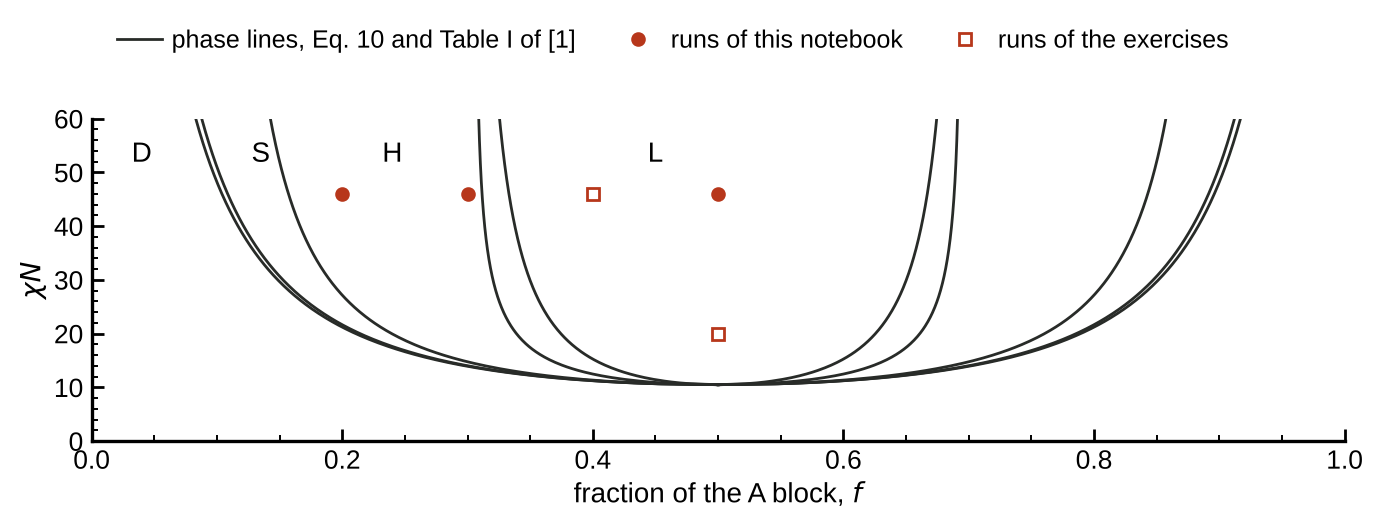

,f at χN = 46,f at χN = 20
phase line,,
D–fcc,0.104,0.211
fcc–bcc,0.109,0.214
bcc–H,0.157,0.240
H–G,0.312,0.339
G–L,0.333,0.374


In [5]:
LINES = {'D–fcc': (1.08, 0.95), 'fcc–bcc': (1.10, 0.96), 'bcc–H': (0.55, 1.20), 'H–G': (-2.5, 2.7),
         'G–L': (1.5, 2.41)}                         # a and b of Table I of [1]


def phase_line(chi_n, a, b):
    """Fraction f of the A block on a mean-field phase line, the lower branch of Eq. 10 of [1]."""
    return 0.5 - 0.5 * np.sqrt(chi_n - 10.5) / (a + b * np.sqrt(chi_n))


chi_n = np.linspace(10.5, 60, 300)
fig, axes = one_panel(left=0.085)
for name, (a, b) in LINES.items():
    f = phase_line(chi_n, a, b)
    axes.plot(f, chi_n, color=C['ink'], lw=1.0)
    axes.plot(1 - f, chi_n, color=C['ink'], lw=1.0)
for f_run, chi_run, marker in [(0.2, 46, 'o'), (0.3, 46, 'o'), (0.5, 46, 'o'), (0.4, 46, 's'), (0.5, 20, 's')]:
    axes.plot(f_run, chi_run, marker, color=C['B'], mfc='none' if marker == 's' else C['B'], mew=1.0)
for label, f_label in [('D', 0.04), ('S', 0.135), ('H', 0.24), ('L', 0.45)]:
    axes.text(f_label, 52, label, ha='center')
axes.set_xlim(0, 1)
axes.set_ylim(0, 60)
axes.set_xlabel(r'fraction of the A block, $f$')
axes.set_ylabel(r'$\chi N$')
top_legend(fig, [Line2D([], [], color=C['ink'], lw=1.0, label='phase lines, Eq. 10 and Table I of [1]'),
                 Line2D([], [], color=C['B'], marker='o', ls='none', label='runs of this notebook'),
                 Line2D([], [], color=C['B'], marker='s', mfc='none', ls='none', label='runs of the exercises')])
fig.savefig(FIGURES / 'phase_diagram.pdf')
plt.show()

pd.DataFrame({'f at χN = 46': [phase_line(46, a, b) for a, b in LINES.values()],
              'f at χN = 20': [phase_line(20, a, b) for a, b in LINES.values()]},
             index=pd.Index(list(LINES), name='phase line')).round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Phase lines (Figure 1).** At χN = 46 the mean-field theory places the transitions between spheres, cylinders,
  gyroid and lamellae at f = 0.16, 0.31 and 0.33 (fcc spheres only in a thin band at f ≈ 0.10 to 0.11), the values
  that [1] quotes. So A<sub>5</sub>B<sub>5</sub> should form lamellae, A<sub>3</sub>B<sub>7</sub> hexagonal cylinders close to
  the gyroid line, and A<sub>2</sub>B<sub>8</sub> spheres close to the cylinder line.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#3D5A80; color:#ffffff; padding:8px 14px; border-radius:6px;">The DPD model of Groot and Madden<br><span style="font-size:0.72em; font-weight:normal;">repulsions from χ, springs, and the size of a homopolymer chain</span></h2>

Groot and Madden [1] modeled the diblocks as strings of N = 10 DPD beads at ρ = 3 with a<sub>AA</sub> =
a<sub>BB</sub> = 25 (notebook 01), joined by harmonic springs F = −C r<sub>ij</sub> with C = 4. The A–B repulsion
comes from χ through the Groot–Warren mapping (notebook 02; Eqs. 7 and 8 of [1]),

$$a_{AB} \approx a_{AA} + 3.27\,\chi \quad (\rho = 3), \qquad a_{AB} \approx a_{AA} + 1.45\,\chi \quad (\rho = 5),$$

so a<sub>AB</sub> = 40 gives χ = 4.59 and χN = 46. Beads joined by a spring also feel the DPD pair forces. The length
scale is fixed by the size of a chain: for a melt of homopolymers of 10 beads, Groot and Madden found a root mean
square end-to-end distance √⟨R²⟩ = 3.01 r<sub>C</sub> at ρ = 3 with C = 4.

Groot and Madden used σ = 3.67 and γ = σ²/2k<sub>B</sub>T = 6.75, with the Groot–Warren integrator of notebook 01.
Here LAMMPS runs the standard velocity-Verlet scheme with Δt = 0.04 τ and the same γ; equilibrium structures do not
depend on γ. The LAMMPS harmonic bond is written as E = K(r − r<sub>0</sub>)², so its force constant is 2K: K = 2 and
r<sub>0</sub> = 0 give C = 4. Groot and Madden ran 24 000 beads in a box of 20³ r<sub>C</sub>³ for 30 000 to 60 000 τ
(Table II of [1]); here the box is 12³ r<sub>C</sub>³ (5180 beads) and each run covers 1000 τ, enough for the first
ordered structures but not for the long equilibration of [1].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code computes χ and a<sub>AB</sub> for χN = 46, and two numbers of [1] for short chains that come back in the discussion.</div>

In [6]:
chi_n_target = 46.0
a_ab = A_II + 3.27 * chi_n_target / CHAIN           # Eq. 7 of [1]
pd.DataFrame({'value': [chi_n_target / CHAIN, a_ab, 10.5 + 41.0 * CHAIN**(-1 / 3),
                        chi_n_target / (1 + 3.9 * CHAIN**(-1 / 3))]},
             index=['χ for χN = 46', 'a_AB at ρ = 3 (Eq. 7 of [1])',
                    'χN at the order–disorder transition for N = 10 (Eq. 11 of [1])',
                    'effective χN of the runs (Eq. 12 of [1])']).round(2)

,value
χ for χN = 46,4.60
a_AB at ρ = 3 (Eq. 7 of [1]),40.04
χN at the order–disorder transition for N = 10 (Eq. 11 of [1]),29.53
effective χN of the runs (Eq. 12 of [1]),16.37


<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the chain builder, the LAMMPS data file and the LAMMPS setup, and <code>positions</code>, which reads the bead positions back from LAMMPS.</div>

In [7]:
def build_melt(n_a, box, seed=1):
    """
    Chains of CHAIN beads as random walks with steps of 0.7 r_C: the first n_a beads of each chain are A (type 1),
    the rest B (type 2). Returns positions, types, molecule numbers and bonds (LAMMPS atom numbers, from 1).
    """
    rng = np.random.default_rng(seed)
    chains = int(RHO * box**3) // CHAIN
    pos, types, molecules, bonds = [], [], [], []
    for chain in range(chains):
        bead = rng.random(3) * box
        for k in range(CHAIN):
            if k > 0:
                step = rng.standard_normal(3)
                bead = pos[-1] + 0.7 * step / np.linalg.norm(step)
                bonds.append([len(pos), len(pos) + 1])
            pos.append(bead.copy())
            types.append(1 if k < n_a else 2)
            molecules.append(chain + 1)
    return np.array(pos) % box, np.array(types), np.array(molecules), np.array(bonds)


def write_data(path, pos, types, molecules, bonds, box):
    """LAMMPS data file (atom style bond) of the melt."""
    lines = [f'diblock melt\n\n{len(pos)} atoms\n{len(bonds)} bonds\n2 atom types\n1 bond types\n',
             f'0 {box} xlo xhi\n0 {box} ylo yhi\n0 {box} zlo zhi\n', 'Masses\n\n1 1.0\n2 1.0\n', 'Atoms # bond\n']
    for index in range(len(pos)):
        x, y, z = pos[index]
        lines.append(f'{index + 1} {molecules[index]} {types[index]} {x:.4f} {y:.4f} {z:.4f}')
    lines.append('\nBonds\n')
    for index, (first, second) in enumerate(bonds):
        lines.append(f'{index + 1} 1 {first} {second}')
    path.write_text('\n'.join(lines) + '\n')


def start_lammps(data_file, a_ab, seed=4321):
    """A LAMMPS instance with the melt of the data file, DPD pair forces and harmonic springs."""
    lmp = lammps(cmdargs=['-log', 'none', '-screen', 'none', '-sf', 'omp', '-pk', 'omp', str(THREADS)])
    lmp.commands_string(f"""
units lj
atom_style bond
# bonds of the soft springs can stretch beyond the pair cutoff: a longer ghost cutoff keeps both beads of every bond
comm_modify vel yes cutoff 4.0
read_data {data_file}
bond_style harmonic
bond_coeff 1 {BOND_K} 0.0
special_bonds lj 1 1 1
pair_style dpd 1.0 1.0 {seed}
pair_coeff 1 1 {A_II} {GAMMA} 1.0
pair_coeff 2 2 {A_II} {GAMMA} 1.0
pair_coeff 1 2 {a_ab} {GAMMA} 1.0
neighbor 0.3 bin
neigh_modify every 1 delay 0 check yes
velocity all create 1.0 {seed + 1} mom yes
timestep {DT}
fix integrate all nve
""")
    return lmp


def positions(lmp, count, box):
    """Positions of all beads, in the order of the atom numbers and wrapped into the box."""
    ids = np.array(lmp.numpy.extract_atom('id'))[:count]
    x = np.array(lmp.numpy.extract_atom('x'))[:count]
    return x[np.argsort(ids)] % box

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The chain model is checked first on a melt of A<sub>10</sub> homopolymers, 3000 beads in a box of 10³
r<sub>C</sub>³, relaxed for 100 τ and sampled for 200 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code runs the homopolymer melt and compares √⟨R²⟩ with [1]; the table also gives the bond lengths and the temperature.</div>

In [8]:
pos_h, types_h, molecules_h, bonds_h = build_melt(CHAIN, 10.0, seed=2)     # all beads A
write_data(WORK / 'homopolymer.data', pos_h, types_h, molecules_h, bonds_h, 10.0)
lmp = start_lammps(WORK / 'homopolymer.data', A_II)
lmp.command('run 2500')                              # 100 tau to relax the random walks

end_to_end, bond_lengths = [], []
start = time.time()
for block in range(20):                              # 20 samples, 10 tau apart
    lmp.command('run 250')
    x = positions(lmp, len(pos_h), 10.0)
    chains = x.reshape(-1, CHAIN, 3)                 # one row per chain, beads in chain order
    vectors = chains[:, 1:] - chains[:, :-1]
    vectors -= 10.0 * np.round(vectors / 10.0)       # minimum image bond vectors
    end_to_end.append(np.sum(vectors, axis=1))
    bond_lengths.append(np.linalg.norm(vectors, axis=2).ravel())
temperature_h = lmp.get_thermo('temp')
lmp.close()
end_to_end, bond_lengths = np.concatenate(end_to_end), np.concatenate(bond_lengths)
print(f'{len(pos_h)} beads, 300 tau in {time.time() - start:.0f} s')
pd.DataFrame({'this notebook': [np.sqrt(np.mean(np.sum(end_to_end**2, axis=1))), np.mean(bond_lengths),
                                np.max(bond_lengths), temperature_h],
              'Groot and Madden [1]': [3.01, np.nan, np.nan, np.nan]},
             index=['√⟨R²⟩ (r_C)', 'mean bond length (r_C)', 'longest bond (r_C)', 'k_BT at the end']).round(3)

3000 beads, 300 tau in 15 s


,this notebook,Groot and Madden [1]
√⟨R²⟩ (r_C),3.005,3.01
mean bond length (r_C),0.908,NaN
longest bond (r_C),2.700,NaN
k_BT at the end,1.025,NaN


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Chain size.** √⟨R²⟩ = 3.01 r<sub>C</sub>, against 3.01 in [1]: the chain model and the units match the model of
  Groot and Madden.
- **Bond lengths.** The springs are soft, with a mean bond length of 0.91 r<sub>C</sub>, but the longest bond
  is 2.7 r<sub>C</sub>, longer than the pair cutoff plus the neighbor skin (1.3 r<sub>C</sub>). LAMMPS keeps
  copies (ghosts) of the beads near the edge of each processor domain only up to that distance by default; a bond
  that reaches further loses its partner, and the run either stops or computes the bond across the wrong periodic
  image. `comm_modify cutoff 4.0` in the setup avoids this. Without it, runs of this model heat up to
  k<sub>B</sub>T ≈ 1.2 instead of stopping, a quiet error worth knowing about.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#9C4F6E; color:#ffffff; padding:8px 14px; border-radius:6px;">Three melts at χN = 46<br><span style="font-size:0.72em; font-weight:normal;">A5B5, A3B7 and A2B8 in LAMMPS, followed by S(q) and clusters</span></h2>

The three melts start from random walks, a fully mixed state, and run for 1000 τ (25 000 steps) at a<sub>AB</sub> =
40. Two measures follow the ordering every 50 τ:

- **Structure factor.** S(q) = |Σ<sub>j</sub> exp(i**q**·**r**<sub>j</sub>)|²/N<sub>A</sub>, summed over the A beads,
  is the strength of a density wave with wave vector **q**. It is about 1 for a random mixture; an ordered structure
  puts a large peak S(q*) at the wave vector of its period d = 2π/|q*|. Scattering experiments measure the same
  quantity.
- **Clusters.** A beads closer than 0.8 r<sub>C</sub> are joined into clusters. Micelles give many clusters, one
  connected network or a set of layers gives a single cluster that holds nearly all A beads.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the structure factor peak, the cluster analysis, <code>run_melt</code> and <code>describe</code>, which applies both measures to every saved frame of a run.</div>

In [9]:
def structure_peak(x_a, box, bins=24):
    """
    Largest value of the structure factor S(q) = |sum exp(i q.r)|^2 / N of the A beads (q not 0), the period
    2 pi / |q| of that wave and its direction, from the A density on a grid. S is about 1 for a random mixture and
    grows with order.
    """
    counts = np.histogramdd(x_a, bins=bins, range=[(0, box)] * 3)[0]
    power = np.abs(np.fft.fftn(counts))**2 / len(x_a)
    power[0, 0, 0] = 0.0
    k = np.fft.fftfreq(bins, d=box / bins)            # wave numbers 1 / wavelength
    peak = np.unravel_index(np.argmax(power), power.shape)
    vector = np.array([k[peak[0]], k[peak[1]], k[peak[2]]])
    return power[peak], 1.0 / np.linalg.norm(vector), vector / np.linalg.norm(vector)


def a_clusters(x_a, box, cutoff=0.8, smallest=10):
    """Sizes of the clusters of A beads (beads closer than the cutoff are joined), largest first."""
    pairs = cKDTree(x_a, boxsize=box).query_pairs(cutoff, output_type='ndarray')
    links = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(len(x_a), len(x_a)))
    labels = connected_components(links, directed=False)[1]
    sizes = np.sort(np.bincount(labels))[::-1]
    return sizes[sizes >= smallest]


def run_melt(n_a, a_ab, total_tau, every_tau=50, seed=1):
    """Builds and runs the melt of A_n B_(10-n) chains; returns the types and the positions every every_tau."""
    pos, types, molecules, bonds = build_melt(n_a, BOX, seed)
    write_data(WORK / f'melt_A{n_a}.data', pos, types, molecules, bonds, BOX)
    lmp = start_lammps(WORK / f'melt_A{n_a}.data', a_ab, seed=4321 + seed)
    frames = [pos]
    start = time.time()
    for block in range(int(total_tau / every_tau)):
        lmp.command(f'run {int(every_tau / DT)}')
        frames.append(positions(lmp, len(pos), BOX))
    print(f'A{n_a}B{CHAIN - n_a}, a_AB = {a_ab:.2f}: {len(pos)} beads, {total_tau:g} tau in {time.time() - start:.0f} s, '
          f'k_BT = {lmp.get_thermo("temp"):.3f}')
    lmp.close()
    return types, frames


def describe(types, frames, every_tau=50):
    """S(q) peak, period and A clusters of every frame of a run."""
    rows = []
    for index, x in enumerate(frames):
        x_a = x[types == 1]
        peak, period, direction = structure_peak(x_a, BOX)
        sizes = a_clusters(x_a, BOX)
        rows.append({'time (τ)': index * every_tau, 'S(q*)': peak, 'period (r_C)': period, 'A clusters': len(sizes),
                     'A in the largest cluster': sizes[0] / len(x_a) if len(sizes) else 0.0})
    return pd.DataFrame(rows).set_index('time (τ)')

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code runs the three melts, 1000 τ each, and analyzes every frame.</div>

In [10]:
melts = {}
for n_a in [5, 3, 2]:
    melts[n_a] = run_melt(n_a, a_ab, total_tau=1000)
history = {n_a: describe(*melts[n_a]) for n_a in melts}

A5B5, a_AB = 40.04: 5180 beads, 1000 tau in 213 s, k_BT = 1.048


A3B7, a_AB = 40.04: 5180 beads, 1000 tau in 188 s, k_BT = 1.042


A2B8, a_AB = 40.04: 5180 beads, 1000 tau in 127 s, k_BT = 1.007


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 2.** Ordering of the three melts at χN = 46: (a) the peak of the structure factor of the A beads and (b) the
fraction of the A beads in the largest A cluster, against time. `figures/ordering.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 2 (<code>figures/ordering.pdf</code>); the table gives both measures, the period and the number of A clusters at the end of each run.</div>

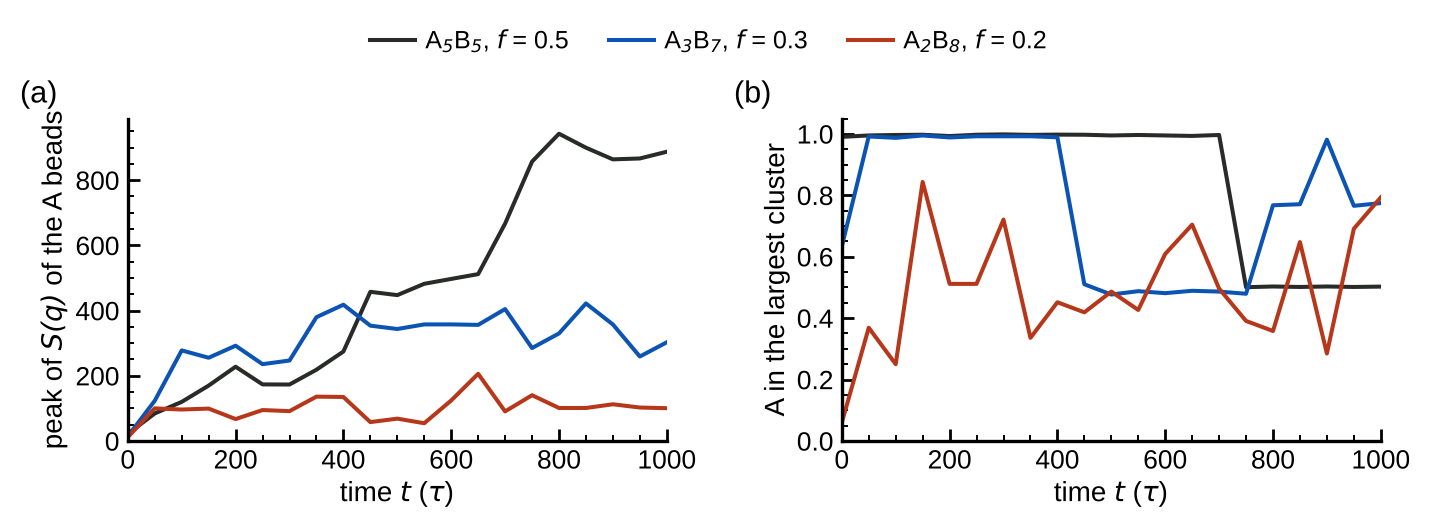

,S(q*),period (r_C),A clusters,A in the largest cluster
A5B5,887.226,6.000,2.0,0.503
A3B7,302.690,5.367,2.0,0.775
A2B8,100.489,5.367,2.0,0.793


In [11]:
fig, left, right = two_panels()
for n_a, color in [(5, C['ink']), (3, C['A']), (2, C['B'])]:
    left.plot(history[n_a].index, history[n_a]['S(q*)'], color=color)
    right.plot(history[n_a].index, history[n_a]['A in the largest cluster'], color=color)
left.set_xlim(0, 1000)
left.set_ylim(0, None)
left.set_xlabel(r'time $t$ ($\tau$)')
left.set_ylabel(r'peak of $S(q)$ of the A beads')
right.set_xlim(0, 1000)
right.set_ylim(0, 1.05)
right.set_xlabel(r'time $t$ ($\tau$)')
right.set_ylabel('A in the largest cluster')
top_legend(fig, [Line2D([], [], color=C['ink'], label='A$_5$B$_5$, $f$ = 0.5'),
                 Line2D([], [], color=C['A'], label='A$_3$B$_7$, $f$ = 0.3'),
                 Line2D([], [], color=C['B'], label='A$_2$B$_8$, $f$ = 0.2')])
fig.savefig(FIGURES / 'ordering.pdf')
plt.show()

pd.DataFrame({f'A{n_a}B{CHAIN - n_a}': history[n_a].iloc[-1] for n_a in history}).T.round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Ordering (Figure 2).** All three melts leave the random start within 50 τ. A<sub>5</sub>B<sub>5</sub> orders in
  two steps and reaches S(q*) ≈ 900 after about 800 τ, with a period of 6.0 r<sub>C</sub>; its A beads form two
  clusters of half the A beads each, two layers. A<sub>3</sub>B<sub>7</sub> reaches S(q*) ≈ 300 within a few hundred
  τ (period 5.4 r<sub>C</sub>), and A<sub>2</sub>B<sub>8</sub> only about 100: small domains give a weaker peak. The
  cluster measure jumps back and forth for these two, since domains closer than 0.8 r<sub>C</sub> merge into one
  cluster for a while and separate again.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#4F772D; color:#ffffff; padding:8px 14px; border-radius:6px;">The structures<br><span style="font-size:0.72em; font-weight:normal;">slices and 3D views of the final configurations</span></h2>

**Figure 3.** Slices 3 r<sub>C</sub> thick and 12 r<sub>C</sub> wide through the middle of the box after 1000 τ,
seen along the box axis or diagonal that lies most nearly along the layers or cylinders: A beads blue, B beads light
red.
`figures/mesophases.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 3 (<code>figures/mesophases.pdf</code>).</div>

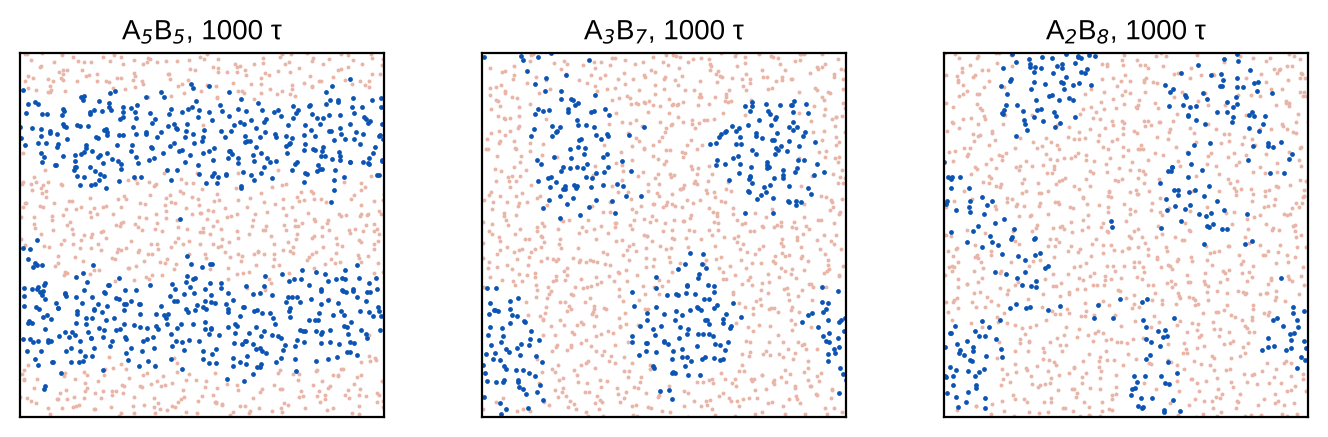

In [12]:
def view_direction(x_a, box, bins=24, peaks=6):
    """
    The direction among the box axes, face diagonals and body diagonals that is most nearly perpendicular to the
    strongest density waves of the A beads: the direction along the layers or cylinders.
    """
    counts = np.histogramdd(x_a, bins=bins, range=[(0, box)] * 3)[0]
    power = np.abs(np.fft.fftn(counts))**2
    power[0, 0, 0] = 0.0
    k = np.fft.fftfreq(bins, d=box / bins)
    strongest = np.argsort(power.ravel())[::-1][:2 * peaks]
    waves = np.array([[k[i] for i in np.unravel_index(index, power.shape)] for index in strongest])
    weights = power.ravel()[strongest]
    best, best_cost = None, np.inf
    for i in (-1, 0, 1):
        for j in (-1, 0, 1):
            for m in (0, 1):
                if (i, j, m) == (0, 0, 0):
                    continue
                direction = np.array([i, j, m]) / np.linalg.norm([i, j, m])
                cost = np.sum(weights * (waves @ direction)**2)
                if cost < best_cost:
                    best, best_cost = direction, cost
    return best


def draw_slice(axes, types, x, title, thickness=3.0):
    """
    Beads in a slab of the given thickness through the box center, seen along view_direction, so that layers and
    cylinders are seen edge-on: A blue, B light red. Periodic images fill the 12 x 12 r_C view.
    """
    normal = view_direction(x[types == 1], BOX)
    helper = np.eye(3)[np.argmin(np.abs(normal))]    # the box axis least parallel to the view direction
    across = np.cross(normal, helper)
    across /= np.linalg.norm(across)
    up = np.cross(normal, across)
    shifts = np.array([[i, j, k] for i in (-1, 0, 1) for j in (-1, 0, 1) for k in (-1, 0, 1)]) * BOX
    images = (x[None, :, :] + shifts[:, None, :]).reshape(-1, 3) - BOX / 2
    kinds = np.tile(types, len(shifts))
    u, v, w = images @ across, images @ up, images @ normal
    inside = (np.abs(w) < thickness / 2) & (np.abs(u) < BOX / 2) & (np.abs(v) < BOX / 2)
    for kind, color, size in [(2, '#E8B5A8', 2), (1, C['A'], 3)]:
        mask = inside & (kinds == kind)
        axes.scatter(u[mask], v[mask], s=size, color=color, lw=0)
    axes.set_xlim(-BOX / 2, BOX / 2)
    axes.set_ylim(-BOX / 2, BOX / 2)
    axes.set_aspect('equal')
    axes.set_xticks([])
    axes.set_yticks([])
    for side in axes.spines.values():                # a thin frame around the slice
        side.set_visible(True)
        side.set_linewidth(0.8)
    panel_title(axes, title)


fig = plt.figure(figsize=(7.0, 2.6))
for column, n_a in enumerate([5, 3, 2]):
    axes = fig.add_axes([0.04 + 0.33 * column, 0.06, 0.26, 0.26 * 7.0 / 2.6])
    types, frames = melts[n_a]
    draw_slice(axes, types, frames[-1], f'A$_{n_a}$B$_{CHAIN - n_a}$, 1000 τ')
fig.savefig(FIGURES / 'mesophases.pdf')
plt.show()

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 1.** The A beads of A<sub>5</sub>B<sub>5</sub>, A<sub>3</sub>B<sub>7</sub> and A<sub>2</sub>B<sub>8</sub>
(top to bottom) after 1000 τ; the B beads are hidden.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the final configurations in 3D (Viewer 1).</div>

In [13]:
symbols = {1: 'N', 2: 'O'}
for n_a in [5, 3, 2]:
    types, frames = melts[n_a]
    show_3d(Atoms([symbols[t] for t in types], positions=frames[-1], cell=[BOX] * 3), {'N': C['A']}, radius=0.3,
            width=420, height=320)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 2.** The A beads of A<sub>3</sub>B<sub>7</sub> from the random start to 1000 τ, one frame every 50 τ.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code plays the A<sub>3</sub>B<sub>7</sub> run as a 3D movie (Viewer 2).</div>

In [ ]:
types, frames = melts[3]
movie = [Atoms([symbols[t] for t in types], positions=x, cell=[BOX] * 3) for x in frames]
show_3d(movie, {'N': C['A']}, radius=0.3, interval_ms=250)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Structures (Figure 3, Viewer 1).** A<sub>5</sub>B<sub>5</sub> forms **lamellae**: two flat A layers and two B
  layers in the box, tilted to fit the periodic box. A<sub>3</sub>B<sub>7</sub> forms **cylinders** of A in a B matrix;
  seen along their axis, they sit on a distorted hexagonal lattice. A<sub>2</sub>B<sub>8</sub> forms small **micelles**
  and short worms of A, not yet ordered on a lattice. This is the order of [1] and of mean-field theory: lamellae,
  cylinders, spheres as f decreases.
- **Formation (Viewer 2).** The A<sub>3</sub>B<sub>7</sub> melt passes through a connected network of A before the
  cylinders separate, the pathway that Groot and Madden describe through connected tubes [1].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6B5B95; color:#ffffff; padding:8px 14px; border-radius:6px;">Simulation against theory<br><span style="font-size:0.72em; font-weight:normal;">short chains, the effective χN and the finite box</span></h2>

Groot and Madden [1] found the order lamellar, perforated lamellar, hexagonal and micellar as f decreases from 0.5,
with the transitions at f ≈ 0.37, 0.31 and 0.25 at χN = 46, against 0.33, 0.31 and 0.16 in mean-field theory. They
traced the difference to two causes:

- **Short chains.** For N = 10 the fluctuations are strong and shift the order–disorder transition upward, to
  (χN)<sub>c</sub> = 10.5 + 41.0 N<sup>−1/3</sup> ≈ 29.5 (Eq. 11 of [1]); the melt behaves as an infinitely long
  polymer at an effective χN that is lower, by Eq. 12 of [1] about 16 for χN = 46. The simulated phase boundaries
  matched mean-field theory at (χN)<sub>eff</sub> = 20 ± 2.
- **The box.** A periodic box allows only periods that fit it. Lamellae and cylinders can tilt to fit (here the
  lamellae run diagonally), but the gyroid has a cubic unit cell that rarely fits, and [1] found the perforated
  lamellar phase where theory predicts the gyroid.

On top of these, the runs here are short. Groot and Madden followed the A<sub>3</sub>B<sub>7</sub> melt from a
connected network of tubes to hexagonal cylinders over tens of thousands of τ and saw the tubes break into rods only
once the rods had aligned.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6D597A; color:#ffffff; padding:8px 14px; border-radius:6px;">Exercises<br><span style="font-size:0.72em; font-weight:normal;">A4B6, a melt at χN = 20 and the mapping at ρ = 5, with solutions</span></h2>

**Exercise 1. A fourth composition.** Predict the structure of A<sub>4</sub>B<sub>6</sub> (f = 0.4) at χN = 46 from
Figure 1, both at χN = 46 and at the effective χN ≈ 20 of [1]. Run it and check.

**Figure 4.** A<sub>4</sub>B<sub>6</sub> at χN = 46: a slice after 1000 τ and the peak of S(q) against time.
`figures/exercise_a4b6.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 1) runs A<sub>4</sub>B<sub>6</sub> for 1000 τ and draws Figure 4 (<code>figures/exercise_a4b6.pdf</code>).</div>

A4B6, a_AB = 40.04: 5180 beads, 1000 tau in 121 s, k_BT = 1.009


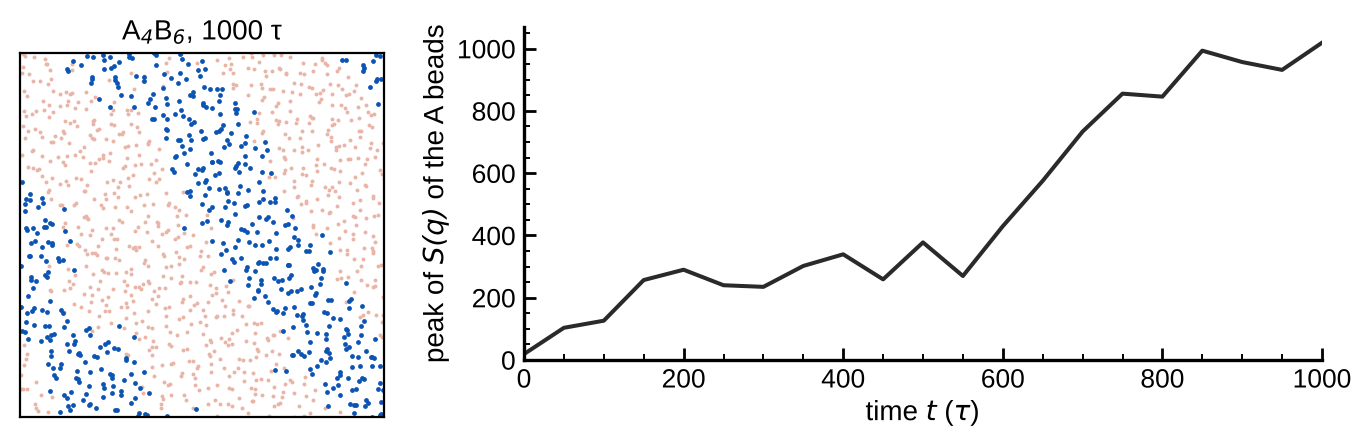

,S(q*),period (r_C),A clusters,A in the largest cluster
time (τ),,,,
1000,1019.102,6.928,1,0.999


In [15]:
# Solution 1
melts[4] = run_melt(4, a_ab, total_tau=1000)
history[4] = describe(*melts[4])
fig = plt.figure(figsize=(7.0, 2.6))
axes = fig.add_axes([0.04, 0.06, 0.26, 0.26 * 7.0 / 2.6])
draw_slice(axes, melts[4][0], melts[4][1][-1], 'A$_4$B$_6$, 1000 τ')
axes = fig.add_axes([0.40, 0.17, 0.57, 0.64])
axes.plot(history[4].index, history[4]['S(q*)'], color=C['ink'])
axes.set_xlim(0, 1000)
axes.set_ylim(0, None)
axes.set_xlabel(r'time $t$ ($\tau$)')
axes.set_ylabel(r'peak of $S(q)$ of the A beads')
fig.savefig(FIGURES / 'exercise_a4b6.pdf')
plt.show()
history[4].iloc[-1:].round(3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 1 (Figure 4).** Both χN = 46 and χN = 20 place f = 0.4 in the lamellar region (the gyroid–lamellar line is
  at f = 0.34 and 0.37), and [1] found lamellae for A<sub>4</sub>B<sub>6</sub>. The run gives lamellae with a period of 6.9 r<sub>C</sub> and S(q*) ≈ 1000; all A beads sit in one
  cluster, since the A layers are joined across the box at this stage.

**Exercise 2. Closer to the transition.** Mean-field theory says that A<sub>5</sub>B<sub>5</sub> orders above χN =
10.5; Eq. 11 of [1] says that chains of 10 beads need χN ≈ 29.5. Run A<sub>5</sub>B<sub>5</sub> at χN = 20
(a<sub>AB</sub> = 31.54) for 600 τ and compare it with the melt at χN = 46 at the same time.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 2) runs A<sub>5</sub>B<sub>5</sub> at χN = 20 and compares both melts at 600 τ.</div>

In [16]:
# Solution 2
a_ab_20 = A_II + 3.27 * 20.0 / CHAIN
melts['χN = 20'] = run_melt(5, a_ab_20, total_tau=600)
history['χN = 20'] = describe(*melts['χN = 20'])
pd.DataFrame({'A5B5, χN = 46': history[5].loc[600], 'A5B5, χN = 20': history['χN = 20'].loc[600]}).T.round(3)

A5B5, a_AB = 31.54: 5180 beads, 600 tau in 75 s, k_BT = 1.034


,S(q*),period (r_C),A clusters,A in the largest cluster
"A5B5, χN = 46",497.091,6.000,1.0,0.995
"A5B5, χN = 20",46.283,5.367,1.0,0.985


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 2.** At 600 τ the melt at χN = 20 has S(q*) ≈ 46, against about 500 at χN = 46: A-rich and B-rich regions
  fluctuate, but no lamellae form. Mean-field theory predicts lamellae at χN = 20; the short chains need more, as
  Eq. 11 of [1] says. A longer run would show whether the melt orders slowly or stays disordered.

**Exercise 3. Another density.** Groot and Madden also ran melts at ρ = 5 with a<sub>AA</sub> = 15. Which
a<sub>AB</sub> gives χ = 4.1 (χN = 41) there?

- **Answer 3.** With Eq. 8 of [1], a<sub>AB</sub> = 15 + 1.45 × 4.1 ≈ 21, the value in Table II of [1]. The same χ needs a much smaller repulsion difference at the higher density, as
  in exercise 2 of notebook 02.

Notebook 04 moves from melts to diblocks in water on a substrate, the coating problem of [6].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#37474F; color:#ffffff; padding:8px 14px; border-radius:6px;">Summary<br><span style="font-size:0.72em; font-weight:normal;">the answers to the four questions</span></h2>

1. **Theory.** Diblock melts microphase separate above χN = 10.5 (mean field), into lamellae, gyroid, cylinders or
   spheres as f decreases from 0.5; Eq. 10 of [1] gives the phase lines of the mean-field diagram.
2. **Model.** Chains of 10 beads with a<sub>AA</sub> = 25, springs with C = 4 and a<sub>AB</sub> = 40 (χN = 46 from
   a<sub>AB</sub> = a<sub>AA</sub> + 3.27χ) reproduce the chain size of [1], √⟨R²⟩ = 3.01 against 3.01.
3. **Structures.** At χN = 46, A<sub>5</sub>B<sub>5</sub> forms lamellae (period 6.0 r<sub>C</sub>),
   A<sub>3</sub>B<sub>7</sub> cylinders and A<sub>2</sub>B<sub>8</sub> micelles within 1000 τ, and
   A<sub>4</sub>B<sub>6</sub> lamellae (exercise 1): the sequence of [1].
4. **Short chains and small boxes.** Chains of 10 beads behave as long chains at a lower effective χN (about 20 for
   χN = 46), and the periodic box selects the periods and orientations that fit it.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">References<br><span style="font-size:0.72em; font-weight:normal;">block copolymer theory and DPD</span></h2>

1. R. D. Groot and T. J. Madden, *J. Chem. Phys.* **108**, 8713–8724 (1998), https://doi.org/10.1063/1.476300.
2. R. D. Groot and P. B. Warren, *J. Chem. Phys.* **107**, 4423–4435 (1997), https://doi.org/10.1063/1.474784.
3. L. Leibler, *Macromolecules* **13**, 1602–1617 (1980).
4. M. W. Matsen and F. S. Bates, *Macromolecules* **29**, 1091–1098 (1996).
5. A. P. Thompson et al., *Comput. Phys. Commun.* **271**, 108171 (2022).
6. K. Hasheminejad, *Computational modelling of block copolymer surface coatings at multiple length scales*, doctoral thesis (2026), http://urn.fi/URN:ISBN:978-952-64-2955-7.

</div>